# Happiness Development Index Visualization

Tylsal2949
10/21/2026

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [8]:
import pandas as pd

df = pd.read_excel("Happiness_Development_Index.csv")

print("Dataset dimensions:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset dimensions: (156, 10)
Column names: ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'StudentID']


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,StudentID
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393,tylsal2949
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410,tylsal2949
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341,tylsal2949
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118,tylsal2949
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298,tylsal2949


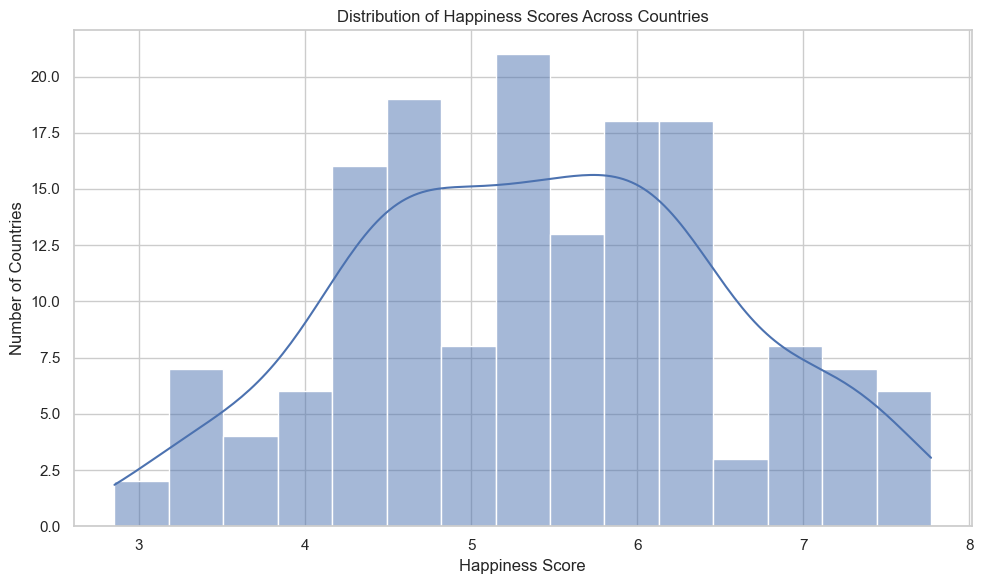

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="Score", bins=15, kde=True)

plt.title("Distribution of Happiness Scores Across Countries")
plt.xlabel("Happiness Score")
plt.ylabel("Number of Countries")
plt.tight_layout()
plt.show()

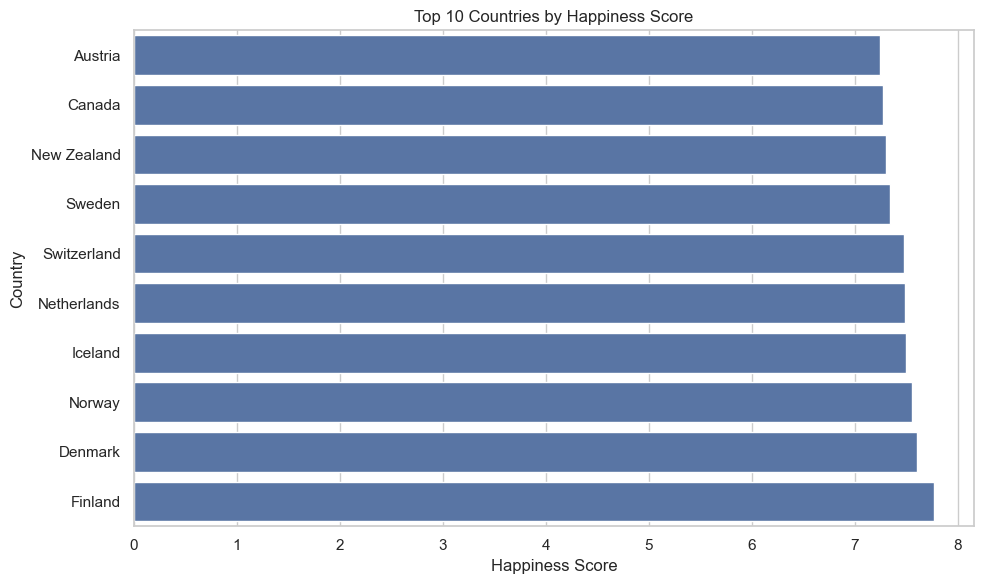

,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246


In [11]:
top10 = df.nlargest(10, "Score").sort_values("Score")

plt.figure(figsize=(10, 6))

sns.barplot(data=top10, x="Score", y="Country or region")

plt.title("Top 10 Countries by Happiness Score")
plt.xlabel("Happiness Score")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(
    df.nlargest(10, "Score")[
        ["Overall rank", "Country or region", "Score"]
    ]
)

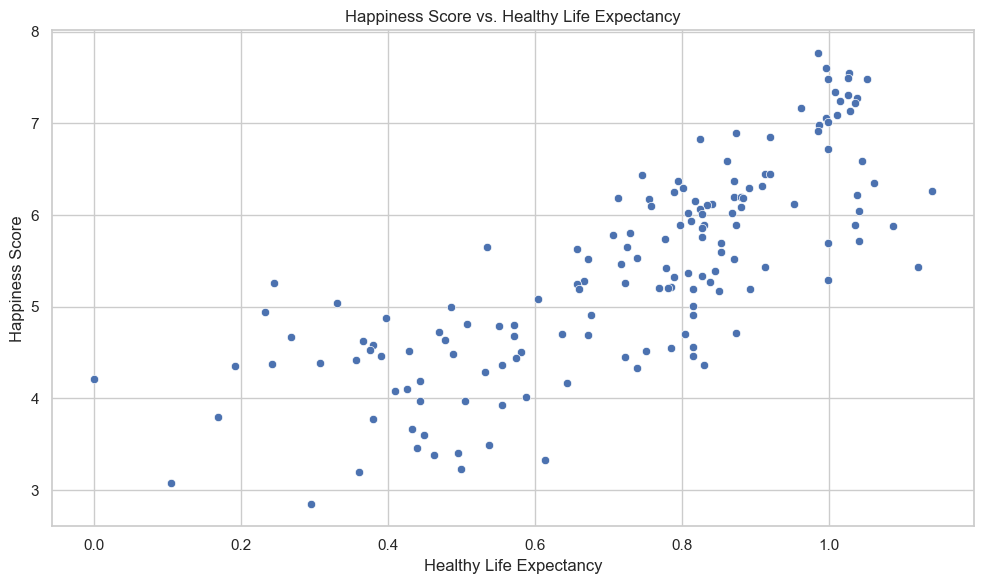

Correlation: 0.7799


In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Healthy life expectancy",
    y="Score"
)

plt.title("Happiness Score vs. Healthy Life Expectancy")
plt.xlabel("Healthy Life Expectancy")
plt.ylabel("Happiness Score")
plt.tight_layout()
plt.show()

correlation = df["Score"].corr(df["Healthy life expectancy"])
print("Correlation:", round(correlation, 4))

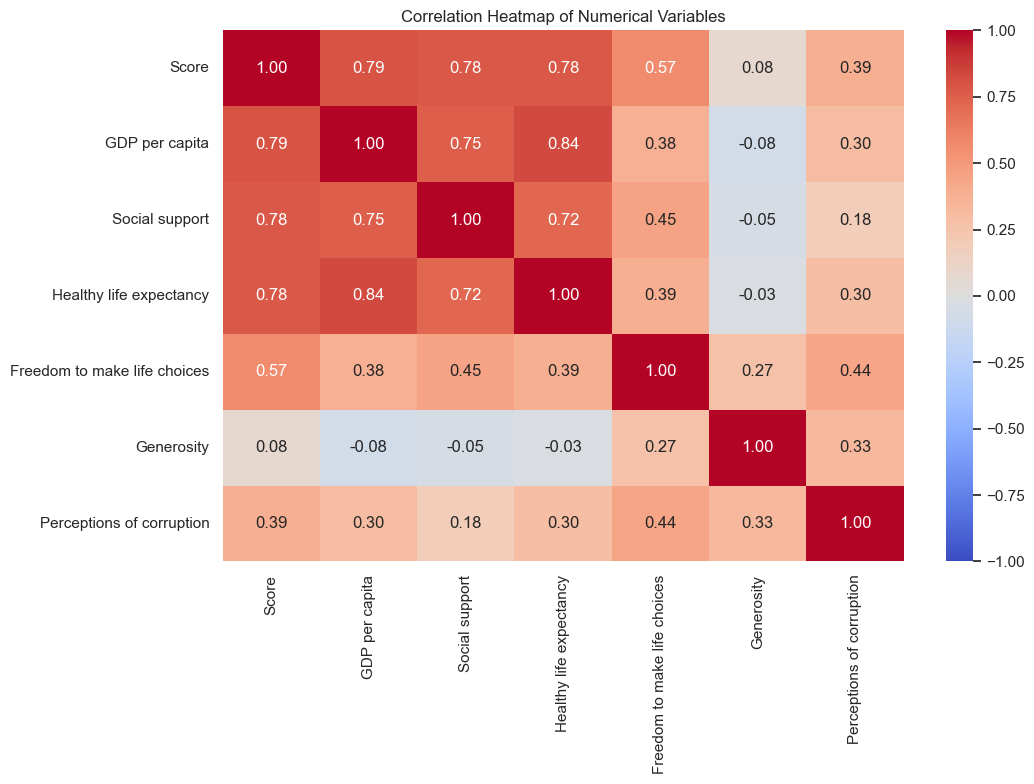

In [13]:
numeric_columns = [
    "Score",
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]

corr = df[numeric_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [14]:
print("DESCRIPTIVE STATISTICS")
display(df["Score"].describe())

print("\nTOP 10 COUNTRIES")
display(
    df.nlargest(10, "Score")[
        ["Overall rank", "Country or region", "Score"]
    ]
)

print("\nCORRELATIONS WITH HAPPINESS SCORE")
print(
    corr["Score"]
    .drop("Score")
    .sort_values(ascending=False)
    .round(4)
)

DESCRIPTIVE STATISTICS


count    156.000000
mean       5.407096
std        1.113120
min        2.853000
25%        4.544500
50%        5.379500
75%        6.184500
max        7.769000
Name: Score, dtype: float64


TOP 10 COUNTRIES


,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246



CORRELATIONS WITH HAPPINESS SCORE
GDP per capita                  0.7939
Healthy life expectancy         0.7799
Social support                  0.7771
Freedom to make life choices    0.5667
Perceptions of corruption       0.3856
Generosity                      0.0758
Name: Score, dtype: float64
